# Phase 4: Model Training: PAE-Weighted GATv2 vs. Baselines
This notebook trains the project's core model, a Graph Attention Network (GATv2) whose edges are weighted by AlphaFold's Predicted Aligned Error, and compares it against four baselines to test whether each piece of the architecture is actually earning its place.

**Inputs:** `clinvar_graph_ready.csv`, `protein_graphs/*.pt` (Phase 3)

**Models trained:**
1. **GATv2 (PAE-weighted)**: the project's proposed model; edge attention is conditioned on `[distance, PAE-confidence]`.
2. **GATv2 (unweighted ablation)**: identical architecture, but edge features are withheld, so it only sees binary contact structure (the gMVP-style baseline this project is positioned against).
3. **GCN (plain baseline)**: a simpler, non-attention graph convolution, also unweighted.
4. **GraphSAGE (additional baseline)**: a different, widely-used non-attention GNN (mean-aggregation over neighbors), broadening architecture coverage beyond a single comparison point.
5. **XGBoost (flat, structure-free baseline)**: sees only the variant's own ESM-2 embedding and amino-acid identities, with no graph/structure at all.

Comparing all five answers two separate questions: *does structure help at all* (GNNs vs. XGBoost), and *does PAE-weighting help beyond structure alone* (model 1 vs. models 2-4), which is this project's specific claim.

**Before running:** restart the kernel and close other heavy applications first. We measured a real, one-time host-RAM spike (~5-6 GB, separate from GPU memory) tied to the first model's training in this environment - not a leak (it partially releases afterward), but worth having headroom for given this machine's 15.8 GB total RAM. We also measured **one full training epoch at ~31 minutes** on this GPU (RTX 4050, 6.4 GB) over the full 34,732-variant training split, this notebook is compute-heavy by design (hyperparameter search + a final tuned run + 3-fold cross-validation on top of the initial comparison) and is intended to run unattended over multiple sessions, not in one sitting.

**Why this notebook does more than report one results table.** An initial pass (Section 8) showed all models performing within ~1-2 points of each other, with the GNNs overfitting within the first few epochs. Rather than stopping there, this notebook: checks *why* (Section 2's PAE-signal diagnostic; Section 8's training curves), tests whether the differences are even statistically real (Section 9) before concluding anything, runs a constrained hyperparameter search and a final tuned training pass that directly targets the overfitting (Sections 10-11), re-tests significance on the tuned models (Section 13), and finally checks how much the tuned model's performance varies across different train/test splits via 3-fold cross-validation (Section 14), a single test-set number alone cannot answer that.

**Outputs:**
- `models/{model_name}_best.pt`: best checkpoint per model, reloadable via the shared `models.py` module
- `figures/*.png`: every figure in this notebook, saved at publication resolution
- `phase4_results_initial.csv` / `phase4_results_final.csv`: comparison tables (AUPRC, AUROC, Precision, Recall, F1) before and after tuning
- `phase4_hyperparameter_search.csv`: every search trial's configuration and validation AUPRC
- `phase4_cv_results.csv`: per-fold and mean±std test metrics from the 3-fold cross-validation
- `phase4_training_history_{model_name}.csv`: per-epoch train/val loss and AUPRC, for overfitting diagnosis
- `phase4_significance_tests_*.csv`: paired statistical test results for every model comparison that matters to this project's claims

**Key sources:**
- Brody, S., Alon, U., & Yahav, E. (2022). *How Attentive Are Graph Attention Networks?* ICLR 2022. [arXiv:2105.14491](https://arxiv.org/abs/2105.14491), defines GATv2.
- Hamilton, W., Ying, Z., & Leskovec, J. (2017). *Inductive Representation Learning on Large Graphs.* NeurIPS 2017. [arXiv:1706.02216](https://arxiv.org/abs/1706.02216), defines GraphSAGE.
- Davis, J. & Goadrich, M. (2006). *The Relationship Between Precision-Recall and ROC Curves.* ICML 2006, motivates AUPRC as the primary metric under class imbalance.
- Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System.* KDD 2016. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785), the flat-feature baseline.
- DeLong, E.R., DeLong, D.M., & Clarke-Pearson, D.L. (1988). *Comparing the areas under two or more correlated receiver operating characteristic curves.* Biometrics, 44(3), 837-845, the paired AUROC significance test.
- McNemar, Q. (1947). *Note on the sampling error of the difference between correlated proportions or percentages.* Psychometrika, 12(2), 153-157, the paired classification-agreement test.
- Kohavi, R. (1995). *A Study of Cross-Validation and Bootstrap for Accuracy Estimation and Model Selection.* IJCAI 1995, motivates k-fold cross-validation for robustness estimation (Section 14).

In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy import stats
from torch.utils.data import Sampler
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                              precision_score, recall_score, f1_score)
from statsmodels.stats.contingency_tables import mcnemar
from tqdm.notebook import tqdm

from missense_dataset import (
    MissenseVariantGraphDataset, NODE_FEATURE_DIM, ESM2_EMBEDDING_DIM, N_AA, AA_1TO_ONEHOT_IDX
)
from models import GATv2Classifier, GCNClassifier, GraphSAGEClassifier

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

GRAPH_DIR = "protein_graphs"
FIGURES_DIR = "figures"
os.makedirs("models", exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.4 GB


## 1. Load Phase 3 Output

In [2]:
df = pd.read_csv("clinvar_graph_ready.csv")
print(f"Total variants : {len(df):,}")
print(f"Unique proteins: {df['UniProt_ID'].nunique():,}")
print(f"  Pathogenic (1): {(df['Target']==1).sum():,}")
print(f"  Benign     (0): {(df['Target']==0).sum():,}")

Total variants : 49,303
Unique proteins: 6,597
  Pathogenic (1): 20,151
  Benign     (0): 29,152


## 2. Diagnostic: Does PAE Actually Carry Enough Signal to Be Useful?
Before training anything, it's worth directly checking the assumption the entire PAE-weighting idea rests on: that PAE varies meaningfully across a protein's edges, giving the attention mechanism something to discriminate on. If most edges end up with nearly the same weight, there is little for the model to learn from, regardless of architecture.

**Why this matters specifically for the transform we used (`1/(1+PAE)`):** AlphaFold's reported PAE rarely goes below ~1 Å even for the most confident residue pairs, which puts a practical *ceiling* on this transform (`1/(1+1) = 0.5`) - the weight can get close to its analytic maximum of 1.0 only when PAE approaches 0, which is uncommon in practice. If a large share of edges sit at or near this ceiling, the transform compresses most of the dataset into a narrow effective range, leaving only the (smaller) population of long-range, less-confident contacts to carry meaningful variation.

In [3]:
rng_diag = np.random.RandomState(0)
sample_proteins_diag = rng_diag.choice(df["UniProt_ID"].unique(), size=300, replace=False)

all_weights = []
per_protein_std = []
for uid in tqdm(sample_proteins_diag, desc="Sampling PAE weights"):
    g = torch.load(os.path.join(GRAPH_DIR, f"{uid}.pt"), weights_only=False)
    w = g.edge_attr[:, 1].numpy()
    all_weights.append(w)
    per_protein_std.append(w.std())
all_weights = np.concatenate(all_weights)

print(f"Sampled {len(sample_proteins_diag)} proteins, {len(all_weights):,} total edges\n")
print(f"Global PAE-weight distribution: min={all_weights.min():.4f} max={all_weights.max():.4f} "
      f"mean={all_weights.mean():.4f} std={all_weights.std():.4f}")
for p in [1, 5, 25, 50, 75, 95, 99]:
    print(f"  p{p:2d}: {np.percentile(all_weights, p):.4f}")

print(f"\nPer-protein std of edge weights: mean={np.mean(per_protein_std):.4f}, "
      f"median={np.median(per_protein_std):.4f}")
print("\nInterpretation: if the 50th/75th/95th percentiles above are all sitting at the same value, most edges\n"
      "are saturated at the practical ceiling of the weight transform, and only a minority of (long-range,\n"
      "low-confidence) edges differ from each other - exactly the kind of limited-signal situation that would\n"
      "explain a PAE-weighted model failing to outperform an unweighted one, independent of training setup.")

Sampling PAE weights:   0%|          | 0/300 [00:00<?, ?it/s]

Sampled 300 proteins, 1,678,270 total edges

Global PAE-weight distribution: min=0.0312 max=0.5000 mean=0.3985 std=0.1205
  p 1: 0.0833
  p 5: 0.1818
  p25: 0.3333
  p50: 0.5000
  p75: 0.5000
  p95: 0.5000
  p99: 0.5000

Per-protein std of edge weights: mean=0.1106, median=0.1156

Interpretation: if the 50th/75th/95th percentiles above are all sitting at the same value, most edges
are saturated at the practical ceiling of the weight transform, and only a minority of (long-range,
low-confidence) edges differ from each other - exactly the kind of limited-signal situation that would
explain a PAE-weighted model failing to outperform an unweighted one, independent of training setup.


## 3. Protein-Level Train / Validation / Test Split
### Why split by protein (UniProt_ID), not by individual variant
Many variants on the same protein share the exact same structural graph. If two variants of the same protein landed in both the training and test sets, the model could effectively 'see' that protein's structure during training and then be evaluated on a held-out variant of a structure it already learned, inflating test performance. Splitting at the protein level guarantees no protein's structure appears in more than one split.

### Why protein (UniProt_ID), specifically, rather than gene symbol
We checked empirically: of the 6,597 proteins in this dataset, **15 UniProt accessions are referenced under two different `GeneSymbol` values** (e.g. `HBA1`/`HBA2`, separate genes encoding an identical protein product). Splitting by gene symbol could place the *same* protein structure in both splits under two different gene names. Splitting by `UniProt_ID` closes this gap.

### A reusable split function
Section 14 needs this same splitting logic repeated under different random seeds for cross-validation, so we define it once as a function (with the disjointness assertion built in as the actual leakage guarantee, not just a comment) rather than duplicating the logic.

In [4]:
def make_protein_split(df, seed, train_frac=0.70, val_frac=0.15):
    """Protein-level train/val/test split. Returns three disjoint-by-protein dataframes."""
    rng = np.random.RandomState(seed)
    unique_proteins = df["UniProt_ID"].unique().copy()
    rng.shuffle(unique_proteins)
    n = len(unique_proteins)
    n_train, n_val = int(n * train_frac), int(n * val_frac)
    train_p = set(unique_proteins[:n_train])
    val_p = set(unique_proteins[n_train:n_train + n_val])
    test_p = set(unique_proteins[n_train + n_val:])
    assert train_p.isdisjoint(val_p) and train_p.isdisjoint(test_p) and val_p.isdisjoint(test_p), \
        "Protein split is not leak-free!"
    train_df = df[df["UniProt_ID"].isin(train_p)].reset_index(drop=True)
    val_df = df[df["UniProt_ID"].isin(val_p)].reset_index(drop=True)
    test_df = df[df["UniProt_ID"].isin(test_p)].reset_index(drop=True)
    return train_df, val_df, test_df


train_df, val_df, test_df = make_protein_split(df, seed=42)
print("Protein-level split is leak-free (verified disjoint by assertion above).")
for name, sub in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    frac = (sub["Target"] == 1).mean()
    print(f"{name:5s}: {len(sub):6,} variants, {sub['UniProt_ID'].nunique():4,} proteins, "
          f"{frac:.3f} pathogenic fraction")

Protein-level split is leak-free (verified disjoint by assertion above).
Train: 34,732 variants, 4,617 proteins, 0.405 pathogenic fraction
Val  :  7,800 variants,  989 proteins, 0.431 pathogenic fraction
Test :  6,771 variants,  991 proteins, 0.402 pathogenic fraction


## 4. Memory-Safe Batching: a Node-Budget Sampler
### Why a fixed batch size (e.g. "16 graphs per batch") is unsafe here
Protein sizes in this dataset range from a handful of residues to 2,699 (Phase 1's cutoff). A fixed *graph-count* batch size doesn't account for this: we measured a real worst case, 16 of our largest proteins landing in the same batch, and it peaked at **7.26 GB**, *exceeding* this machine's 6.44 GB of GPU memory.

### The fix: cap total nodes per batch, not graphs per batch
`NodeBudgetBatchSampler` greedily packs variants into a batch until adding the next one would exceed a fixed **node budget**, bounding peak memory deterministically regardless of shuffle order. Verified under an adversarial worst-case ordering: peak memory **3.47 GB**.

In [5]:
class NodeBudgetBatchSampler(Sampler):
    """
    Yields batches of dataset indices such that the total node count (sum of protein lengths) in any
    one batch never exceeds max_nodes_per_batch - bounding peak GPU memory regardless of which large
    proteins happen to land next to each other after shuffling.
    """

    def __init__(self, node_counts, max_nodes_per_batch=20000, shuffle=True, seed=0):
        self.node_counts = node_counts
        self.max_nodes_per_batch = max_nodes_per_batch
        self.shuffle = shuffle
        self.seed = seed
        self._epoch = 0

    def __iter__(self):
        indices = list(range(len(self.node_counts)))
        if self.shuffle:
            r = random.Random(self.seed + self._epoch)
            r.shuffle(indices)
            self._epoch += 1

        batch, current = [], 0
        for idx in indices:
            n = self.node_counts[idx]
            if batch and current + n > self.max_nodes_per_batch:
                yield batch
                batch, current = [], 0
            batch.append(idx)
            current += n
        if batch:
            yield batch

    def __len__(self):
        total = sum(self.node_counts)
        return max(1, total // self.max_nodes_per_batch)


def get_node_counts(variant_df, graph_dir):
    """Protein length (node count) for each variant, read from its cached graph - no extra computation."""
    cache = {}
    counts = []
    for uid in variant_df["UniProt_ID"]:
        if uid not in cache:
            g = torch.load(os.path.join(graph_dir, f"{uid}.pt"), weights_only=False)
            cache[uid] = g.num_residues
        counts.append(cache[uid])
    return counts


def make_loaders(train_df, val_df, test_df, max_nodes_per_batch=20000):
    """Builds the three DataLoaders for one split - reused for the main split and each CV fold."""
    train_ds = MissenseVariantGraphDataset(train_df, GRAPH_DIR)
    val_ds = MissenseVariantGraphDataset(val_df, GRAPH_DIR)
    test_ds = MissenseVariantGraphDataset(test_df, GRAPH_DIR)
    train_loader = DataLoader(train_ds, batch_sampler=NodeBudgetBatchSampler(
        get_node_counts(train_df, GRAPH_DIR), max_nodes_per_batch, shuffle=True, seed=42))
    val_loader = DataLoader(val_ds, batch_sampler=NodeBudgetBatchSampler(
        get_node_counts(val_df, GRAPH_DIR), max_nodes_per_batch, shuffle=False))
    test_loader = DataLoader(test_ds, batch_sampler=NodeBudgetBatchSampler(
        get_node_counts(test_df, GRAPH_DIR), max_nodes_per_batch, shuffle=False))
    return train_loader, val_loader, test_loader


MAX_NODES_PER_BATCH = 20000
train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df, MAX_NODES_PER_BATCH)
print(f"Approx. batches per epoch - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

Approx. batches per epoch - train: 1741, val: 382, test: 308


## 5. Model Architecture
### The GATv2 layer and PAE-weighting
`GATv2Conv` (Brody et al., 2022) accepts an `edge_dim` argument, letting each edge's feature vector here, `[Cα distance, PAE-derived confidence]` from Phase 3, directly influence the attention score the model learns for that edge.

### Reading out a *variant* prediction from a *protein-wide* graph
Each graph covers the whole protein, but we only need one prediction: is *this specific substitution* pathogenic? After message passing, we read out the embedding of only the mutated residue's node and feed that single vector into a small classifier head, rather than pooling over the entire graph, which would dilute the variant's local signal across a (sometimes 1,000+ residue) protein.

**Implementation note (validated empirically before use):** PyTorch Geometric batches multiple variable-sized graphs into one combined graph, offsetting node indices per graph (`batch.ptr`). We recover each graph's mutated-residue embedding via `batch.ptr[:-1] + variant_node_idx`, confirmed to produce *bit-for-bit identical* output to running each graph through the model one at a time.

### Where the model classes actually live
`GATv2Classifier`, `GCNClassifier`, and `GraphSAGEClassifier` are defined in `models.py`, not pasted into this notebook, so a saved checkpoint can be reloaded later by importing the exact same class definition used during training.

### The ablation and baselines
- **GATv2 (unweighted)**: identical code, `edge_dim=None` isolates the effect of PAE-weighting specifically.
- **GCN**: a non-attention convolution baseline, tests whether attention itself matters.
- **GraphSAGE**: a second, architecturally different non-attention baseline (mean-aggregation over sampled neighbors, Hamilton et al., 2017) broadens the comparison beyond a single non-attention architecture, so a GATv2 win (or loss) isn't an artifact of comparing against only one alternative.
- **XGBoost (Section 7)**: no graph at all, tests whether structure matters at all.

## 6. Handling Class Imbalance & Training Setup
### Why AUPRC, not accuracy, drives model selection
Our classes are imbalanced (~40% pathogenic / 60% benign). **AUPRC** is far more informative under imbalance than accuracy. It is therefore the primary metric for model selection and early stopping; AUROC, Precision, Recall, and F1 are reported alongside.

### Loss function
Binary cross-entropy with a `pos_weight` term from the training split's class ratio, applied identically across every model.

### Early stopping, calibrated not to cut training short
Up to 60 epochs, stopping only after 10 consecutive epochs with no validation AUPRC improvement, evaluated using the *best* validation-AUPRC checkpoint.

### A practical constraint that shapes the rest of this notebook
We measured one full training epoch at **~31 minutes** on this hardware. Every subsequent design choice in this notebook (a *constrained* hyperparameter search rather than an exhaustive grid; 3-fold rather than 5-fold cross-validation, applied only to the model the paper's claim rests on) is calibrated against this real number, not against what would be ideal with unlimited compute.

In [6]:
train_pos = (train_df["Target"] == 1).sum()
train_neg = (train_df["Target"] == 0).sum()
pos_weight_value = train_neg / train_pos
print(f"Training class balance: {train_pos:,} pathogenic / {train_neg:,} benign -> pos_weight = {pos_weight_value:.3f}")
POS_WEIGHT = torch.tensor([pos_weight_value], dtype=torch.float, device=DEVICE)

Training class balance: 14,064 pathogenic / 20,668 benign -> pos_weight = 1.470


In [ ]:
def make_pos_weight(train_df):
    pos = (train_df["Target"] == 1).sum()
    neg = (train_df["Target"] == 0).sum()
    return torch.tensor([neg / pos], dtype=torch.float, device=DEVICE)


def run_epoch(model, loader, pos_weight, optimizer=None):
    """One pass over `loader`. Trains if optimizer is given, otherwise runs in eval mode."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    losses, all_logits, all_labels = [], [], []
    with torch.set_grad_enabled(is_train):
        for batch in loader:
            batch = batch.to(DEVICE)
            if is_train:
                optimizer.zero_grad()
            logits = model(batch)
            loss = nn.functional.binary_cross_entropy_with_logits(logits, batch.y, pos_weight=pos_weight)
            if is_train:
                loss.backward()
                optimizer.step()
            losses.append(loss.item())
            all_logits.extend(logits.detach().cpu().numpy().tolist())
            all_labels.extend(batch.y.detach().cpu().numpy().tolist())

    auprc = average_precision_score(all_labels, all_logits)
    auroc = roc_auc_score(all_labels, all_logits)
    return float(np.mean(losses)), auprc, auroc


def train_model(model, model_name, train_loader, val_loader, pos_weight, n_epochs=60, patience=10,
                lr=1e-3, weight_decay=1e-5, save_checkpoint=True, verbose=True, resume=True):
    checkpoint_path = os.path.join("models", f"{model_name}_best.pt")
    history_path = f"phase4_training_history_{model_name}.csv"

    # Resumability: given this notebook's total runtime (measured ~31 min/epoch), an interruption partway
    # through is a real risk across multiple sessions. If a finished run for this exact model_name already
    # exists, skip retraining entirely and just reload it, the same skip-if-cached pattern used for
    # AlphaFold downloads and ESM-2 embeddings in Phases 2-3.
    # IMPORTANT: we require BOTH the checkpoint AND the history file to exist, not just the checkpoint.
    # The checkpoint is saved on every improving epoch (so a run interrupted mid-training, e.g. a system
    # crash, can leave a checkpoint behind that is only a partial, possibly under-trained snapshot).
    # history_path is only written once at the very end of a successfully completed training loop, so its
    # presence is the real signal that this model actually finished, not just that it got partway through.
    if resume and save_checkpoint and os.path.exists(checkpoint_path) and os.path.exists(history_path):
        model.to(DEVICE)
        model.load_state_dict(torch.load(checkpoint_path, weights_only=True))
        if verbose:
            print(f"[{model_name}] Found existing checkpoint - skipping training and reloading it. "
                  f"Delete {checkpoint_path} first if you want to retrain from scratch.")
        history_df = pd.read_csv(history_path) if os.path.exists(history_path) else pd.DataFrame()
        best_val_auprc = history_df["val_auprc"].max() if len(history_df) else float("nan")
        return model, history_df, best_val_auprc

    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_auprc = -1.0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, n_epochs + 1):
        train_loss, train_auprc, train_auroc = run_epoch(model, train_loader, pos_weight, optimizer)
        val_loss, val_auprc, val_auroc = run_epoch(model, val_loader, pos_weight, optimizer=None)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_auprc": train_auprc,
                         "train_auroc": train_auroc, "val_loss": val_loss, "val_auprc": val_auprc,
                         "val_auroc": val_auroc})
        if verbose:
            print(f"[{model_name}] epoch {epoch:2d}: train_loss={train_loss:.4f} train_AUPRC={train_auprc:.3f} "
                  f"| val_loss={val_loss:.4f} val_AUPRC={val_auprc:.3f} val_AUROC={val_auroc:.3f}")

        if val_auprc > best_val_auprc:
            best_val_auprc = val_auprc
            epochs_without_improvement = 0
            if save_checkpoint:
                torch.save(model.state_dict(), checkpoint_path)
            else:
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                if verbose:
                    print(f"[{model_name}] Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
                break

    if save_checkpoint:
        model.load_state_dict(torch.load(checkpoint_path, weights_only=True))
    else:
        model.load_state_dict(best_state)
    history_df = pd.DataFrame(history)
    if save_checkpoint:
        history_df.to_csv(history_path, index=False)

    del optimizer
    if DEVICE == "cuda":
        torch.cuda.empty_cache()  # this notebook trains many models in one session, release each model's
        # cached GPU allocations before starting the next, rather than letting them accumulate.
    return model, history_df, best_val_auprc


def plot_training_curves(history_df, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="train loss")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="val loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title(f"{model_name}: Loss")
    axes[0].legend()

    axes[1].plot(history_df["epoch"], history_df["train_auprc"], label="train AUPRC")
    axes[1].plot(history_df["epoch"], history_df["val_auprc"], label="val AUPRC")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUPRC"); axes[1].set_title(f"{model_name}: AUPRC")
    axes[1].legend()
    plt.tight_layout()
    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "").replace(",", "")
    fig.savefig(os.path.join(FIGURES_DIR, f"training_curves_{safe_name}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)  # this notebook produces many figures in one session, release each one rather than
    # letting matplotlib keep every figure object alive in memory until the kernel restarts.


def full_metrics(labels, probs, threshold=0.5):
    preds = (np.asarray(probs) >= threshold).astype(int)
    return {
        "AUPRC": average_precision_score(labels, probs),
        "AUROC": roc_auc_score(labels, probs),
        "Precision": precision_score(labels, preds, zero_division=0),
        "Recall": recall_score(labels, preds, zero_division=0),
        "F1": f1_score(labels, preds, zero_division=0),
    }


def evaluate_gnn(model, loader):
    """Returns (labels, probabilities) for every example in loader, in evaluation mode."""
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch)
            all_logits.extend(logits.cpu().numpy().tolist())
            all_labels.extend(batch.y.cpu().numpy().tolist())
    probs = torch.sigmoid(torch.tensor(all_logits)).numpy()
    return np.array(all_labels), probs

## 7. Initial Training Pass: All Five Models, Default Hyperparameters
These are the project's first results, with no tuning. Section 9 checks whether the differences between them are even statistically real; Sections 10-11 revisit training itself after diagnosing the overfitting visible in each GNN's training curve below.

[gatv2_pae_weighted] Found existing checkpoint - skipping training and reloading it. Delete models\gatv2_pae_weighted_best.pt first if you want to retrain from scratch.


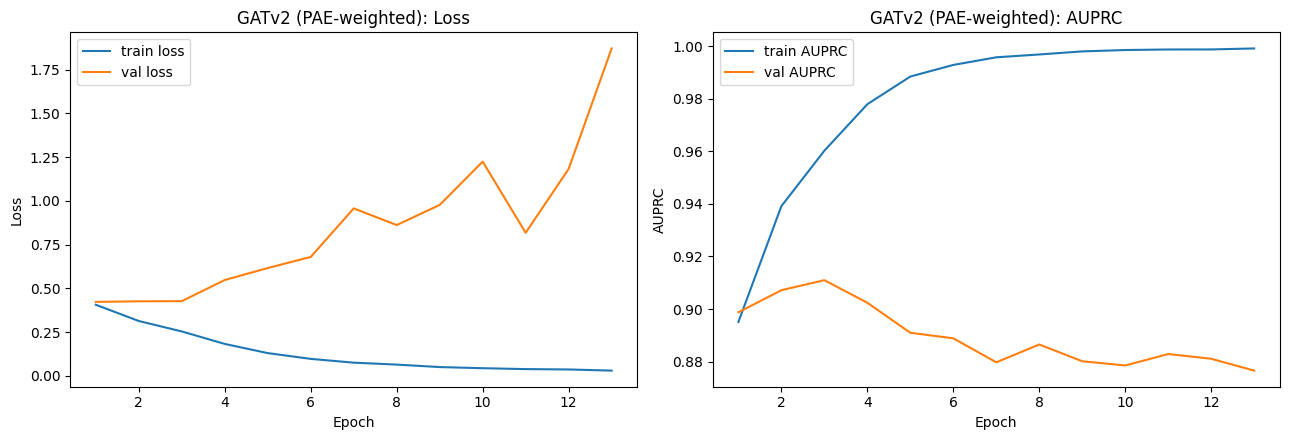

In [8]:
model_pae = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=True)
model_pae, history_pae, _ = train_model(model_pae, "gatv2_pae_weighted", train_loader, val_loader, POS_WEIGHT)
plot_training_curves(history_pae, "GATv2 (PAE-weighted)")

[gatv2_unweighted] Found existing checkpoint - skipping training and reloading it. Delete models\gatv2_unweighted_best.pt first if you want to retrain from scratch.


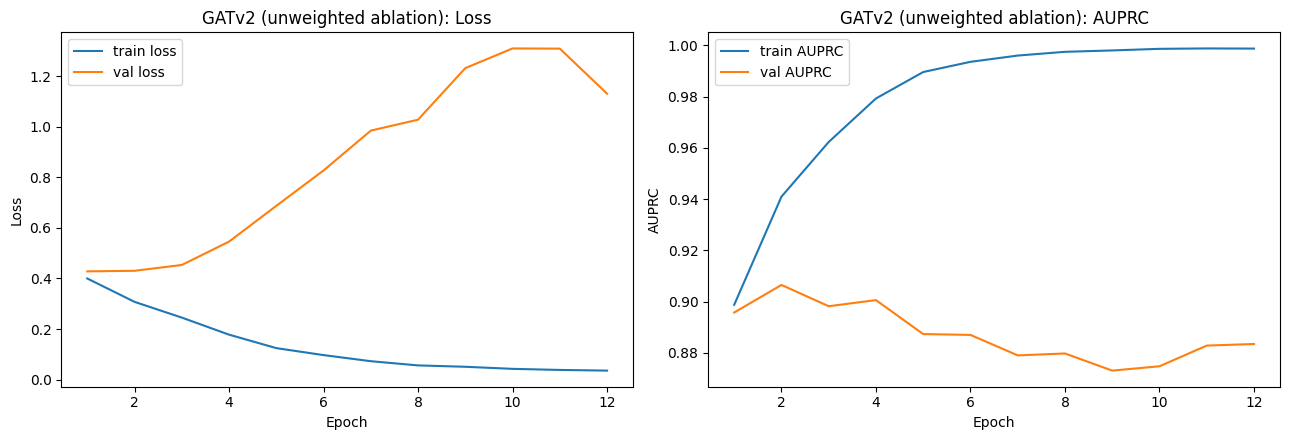

In [9]:
model_unweighted = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=False)
model_unweighted, history_unweighted, _ = train_model(
    model_unweighted, "gatv2_unweighted", train_loader, val_loader, POS_WEIGHT)
plot_training_curves(history_unweighted, "GATv2 (unweighted ablation)")

[gcn_baseline] Found existing checkpoint - skipping training and reloading it. Delete models\gcn_baseline_best.pt first if you want to retrain from scratch.


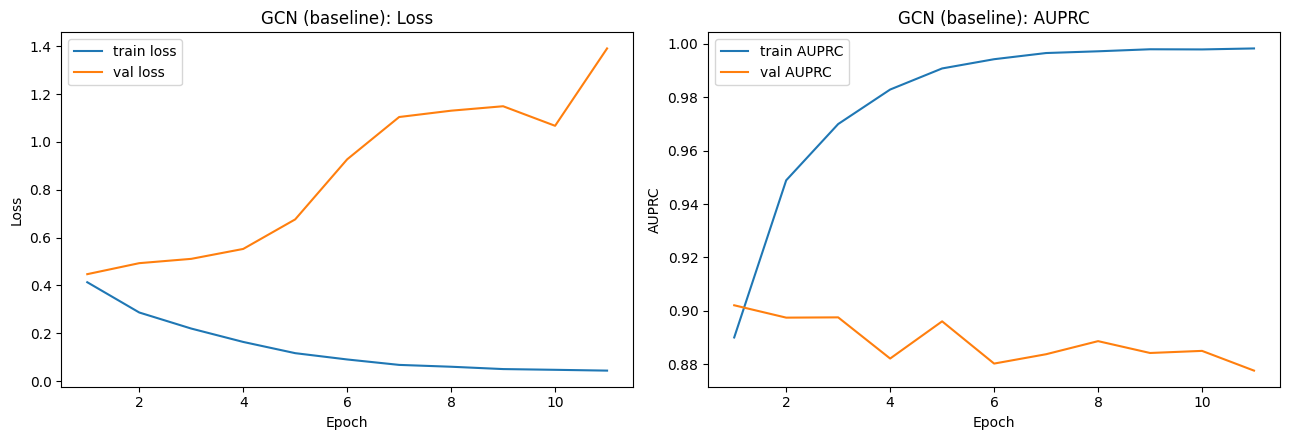

In [10]:
model_gcn = GCNClassifier(in_dim=NODE_FEATURE_DIM)
model_gcn, history_gcn, _ = train_model(model_gcn, "gcn_baseline", train_loader, val_loader, POS_WEIGHT)
plot_training_curves(history_gcn, "GCN (baseline)")

[graphsage_baseline] Found existing checkpoint - skipping training and reloading it. Delete models\graphsage_baseline_best.pt first if you want to retrain from scratch.


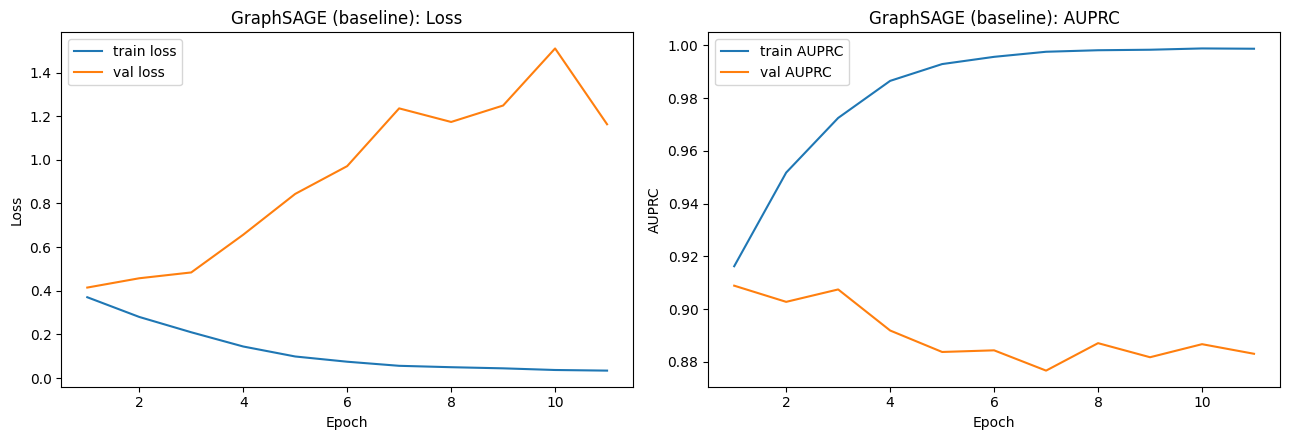

In [11]:
model_sage = GraphSAGEClassifier(in_dim=NODE_FEATURE_DIM)
model_sage, history_sage, _ = train_model(model_sage, "graphsage_baseline", train_loader, val_loader, POS_WEIGHT)
plot_training_curves(history_sage, "GraphSAGE (baseline)")

### XGBoost (Structure-Free Baseline)
This baseline sees **no graph at all**, only the mutated residue's own ESM-2 embedding, its wild-type identity, and its substituted identity. If the GNN models substantially outperform this baseline, that is direct evidence that 3D structural context adds real predictive value beyond sequence/identity features alone.

In [12]:
def extract_flat_features(variant_df, graph_dir):
    """Per-variant feature vector: ESM-2 embedding + WT one-hot + Alt-AA one-hot at the variant's node only."""
    cache = {}
    rows = []
    for _, row in tqdm(variant_df.iterrows(), total=len(variant_df), desc="Extracting flat features"):
        uid = row["UniProt_ID"]
        if uid not in cache:
            cache[uid] = torch.load(os.path.join(graph_dir, f"{uid}.pt"), weights_only=False)
        g = cache[uid]
        node_idx = int(row["Pos"]) - 1
        esm_emb = g.x[node_idx, :ESM2_EMBEDDING_DIM].numpy()
        wt_onehot = g.x[node_idx, ESM2_EMBEDDING_DIM:ESM2_EMBEDDING_DIM + N_AA].numpy()
        alt_onehot = np.zeros(N_AA, dtype=np.float32)
        alt_onehot[AA_1TO_ONEHOT_IDX[row["Alt_AA_1"]]] = 1.0
        rows.append(np.concatenate([esm_emb, wt_onehot, alt_onehot]))
        if len(cache) > 64:
            cache.pop(next(iter(cache)))
    return np.stack(rows)


X_train = extract_flat_features(train_df, GRAPH_DIR)
X_val = extract_flat_features(val_df, GRAPH_DIR)
X_test = extract_flat_features(test_df, GRAPH_DIR)
y_train, y_val, y_test = train_df["Target"].values, val_df["Target"].values, test_df["Target"].values
print("Flat feature matrix shapes:", X_train.shape, X_val.shape, X_test.shape)

Extracting flat features:   0%|          | 0/34732 [00:00<?, ?it/s]

Extracting flat features:   0%|          | 0/7800 [00:00<?, ?it/s]

Extracting flat features:   0%|          | 0/6771 [00:00<?, ?it/s]

Flat feature matrix shapes: (34732, 1320) (7800, 1320) (6771, 1320)


In [13]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    scale_pos_weight=pos_weight_value, eval_metric="logloss", early_stopping_rounds=20, random_state=42,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]
print("XGBoost val :", full_metrics(y_val, xgb_val_probs))
print("XGBoost test:", full_metrics(y_test, xgb_test_probs))

XGBoost val : {'AUPRC': 0.9063037191580755, 'AUROC': 0.9290769219531028, 'Precision': 0.8459603898145237, 'Recall': 0.800178412132025, 'F1': 0.8224327628361858}
XGBoost test: {'AUPRC': 0.9124825004365898, 'AUROC': 0.9353865030096076, 'Precision': 0.8265454545454546, 'Recall': 0.8344346549192364, 'F1': 0.8304713189623676}


## 8. Initial Comparison: AUPRC, AUROC, Precision, Recall, F1
Each GNN was restored from its best validation-AUPRC checkpoint before evaluation. Precision/Recall/F1 are reported at the default 0.5 probability threshold.

In [14]:
test_labels_pae, test_probs_pae = evaluate_gnn(model_pae, test_loader)
test_labels_unw, test_probs_unw = evaluate_gnn(model_unweighted, test_loader)
test_labels_gcn, test_probs_gcn = evaluate_gnn(model_gcn, test_loader)
test_labels_sage, test_probs_sage = evaluate_gnn(model_sage, test_loader)
# all loaders iterate test_ds in the same fixed (non-shuffled) order, so labels align across models
assert (np.array_equal(test_labels_pae, test_labels_unw) and np.array_equal(test_labels_pae, test_labels_gcn)
        and np.array_equal(test_labels_pae, test_labels_sage))

initial_results = []
for name, probs in [("GATv2 (PAE-weighted)", test_probs_pae),
                     ("GATv2 (unweighted ablation)", test_probs_unw),
                     ("GCN (baseline)", test_probs_gcn),
                     ("GraphSAGE (baseline)", test_probs_sage),
                     ("XGBoost (structure-free baseline)", xgb_test_probs)]:
    initial_results.append({"model": name, **full_metrics(test_labels_pae, probs)})

initial_results_df = pd.DataFrame(initial_results).sort_values("AUPRC", ascending=False)
initial_results_df.to_csv("phase4_results_initial.csv", index=False)
print(initial_results_df.to_string(index=False))

                            model    AUPRC    AUROC  Precision   Recall       F1
             GraphSAGE (baseline) 0.914849 0.939311   0.799338 0.886197 0.840529
XGBoost (structure-free baseline) 0.912483 0.935387   0.826545 0.834435 0.830471
             GATv2 (PAE-weighted) 0.911198 0.937346   0.831836 0.849853 0.840748
      GATv2 (unweighted ablation) 0.911158 0.935842   0.778497 0.882526 0.827254
                   GCN (baseline) 0.893764 0.926464   0.808029 0.812775 0.810395


## 9. Are These Differences Even Statistically Real?
The models above differ by only ~0.01-0.02 AUPRC from each other. Before treating any of that as evidence about PAE-weighting or structure, we need to know whether it's a real difference or noise from which 6,771 variants happened to land in this particular test set.

### Why a *paired* test, specifically
All models were scored on the exact same test variants - their predictions are correlated. A paired test exploits that correlation directly, giving a more powerful answer than comparing independent confidence intervals.

### Three complementary tests
- **McNemar's test** compares binary correct/incorrect calls on the same instances - coarse, threshold-dependent.
- **Paired bootstrap on the AUPRC difference** resamples the test set with replacement, computing `AUPRC(A) - AUPRC(B)` each time - uses the full ranking, not one threshold.
- **DeLong's test** (DeLong et al., 1988) is the standard paired test for two correlated AUROC curves.

We report all three because they can disagree, and disagreement is informative: rank-based tests (bootstrap, DeLong) have more statistical power than a threshold-based test (McNemar's).

In [15]:
def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_test(probs_a, probs_b, labels):
    """
    Paired DeLong test for two correlated AUROCs (DeLong et al., 1988).
    IMPORTANT: midranks for the combined array must be computed with all positives ordered before all
    negatives - the AUC formula below only holds under that ordering (caught and fixed during validation
    by cross-checking against sklearn's roc_auc_score, asserted below).
    """
    labels = np.asarray(labels)
    order = np.argsort(-labels)
    m = int(np.sum(labels == 1))
    n = int(np.sum(labels == 0))
    preds_list = [np.asarray(probs_a), np.asarray(probs_b)]
    k = len(preds_list)
    tx = np.empty([k, m]); ty = np.empty([k, n]); tz = np.empty([k, m + n])
    for r in range(k):
        preds_ordered = preds_list[r][order]
        tx[r, :] = compute_midrank(preds_ordered[:m])
        ty[r, :] = compute_midrank(preds_ordered[m:])
        tz[r, :] = compute_midrank(preds_ordered)
    aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    delongcov = np.cov(v01) / m + np.cov(v10) / n

    assert abs(aucs[0] - roc_auc_score(labels, probs_a)) < 1e-6, "DeLong AUC mismatch vs sklearn - do not trust result"
    assert abs(aucs[1] - roc_auc_score(labels, probs_b)) < 1e-6, "DeLong AUC mismatch vs sklearn - do not trust result"

    l = np.array([1, -1])
    z = l.dot(aucs) / np.sqrt(l.dot(delongcov).dot(l))
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return {"auc_a": aucs[0], "auc_b": aucs[1], "z": z, "p_value": p}


def paired_bootstrap_auprc(probs_a, probs_b, labels, n_boot=2000, seed=0):
    rng_b = np.random.RandomState(seed)
    labels = np.asarray(labels); probs_a = np.asarray(probs_a); probs_b = np.asarray(probs_b)
    n_test = len(labels)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng_b.randint(0, n_test, n_test)
        diffs[i] = (average_precision_score(labels[idx], probs_a[idx])
                    - average_precision_score(labels[idx], probs_b[idx]))
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    p_value = 2 * min((diffs > 0).mean(), (diffs < 0).mean())
    return {"mean_diff": diffs.mean(), "ci_low": ci_low, "ci_high": ci_high, "p_value": p_value}


def mcnemar_test(probs_a, probs_b, labels, threshold=0.5):
    preds_a = (np.asarray(probs_a) >= threshold).astype(int)
    preds_b = (np.asarray(probs_b) >= threshold).astype(int)
    correct_a = preds_a == labels
    correct_b = preds_b == labels
    table = [[int(np.sum(correct_a & correct_b)), int(np.sum(correct_a & ~correct_b))],
             [int(np.sum(~correct_a & correct_b)), int(np.sum(~correct_a & ~correct_b))]]
    result = mcnemar(table, exact=False, correction=True)
    return {"table": table, "statistic": result.statistic, "p_value": result.pvalue}


def run_all_significance_tests(name_a, probs_a, name_b, probs_b, labels):
    mc = mcnemar_test(probs_a, probs_b, labels)
    bs = paired_bootstrap_auprc(probs_a, probs_b, labels)
    dl = delong_test(probs_a, probs_b, labels)
    print(f"\n=== {name_a}  vs.  {name_b} ===")
    print(f"McNemar's test           : statistic={mc['statistic']:.3f}, p={mc['p_value']:.4f}")
    print(f"Paired bootstrap (AUPRC) : diff={bs['mean_diff']:+.4f}, 95% CI=[{bs['ci_low']:+.4f}, {bs['ci_high']:+.4f}], p={bs['p_value']:.4f}")
    print(f"DeLong's test (AUROC)    : z={dl['z']:.3f}, p={dl['p_value']:.4f}")
    significant = bs["p_value"] < 0.05 or dl["p_value"] < 0.05
    print(f"-> {'STATISTICALLY SIGNIFICANT' if significant else 'NOT statistically significant'} "
          f"difference between {name_a} and {name_b} (alpha=0.05, using the more powerful rank-based tests)")
    return {"comparison": f"{name_a} vs {name_b}", "mcnemar_p": mc["p_value"],
            "bootstrap_auprc_diff": bs["mean_diff"], "bootstrap_ci_low": bs["ci_low"],
            "bootstrap_ci_high": bs["ci_high"], "bootstrap_p": bs["p_value"],
            "delong_z": dl["z"], "delong_p": dl["p_value"], "significant": significant}

In [16]:
significance_results = []
significance_results.append(run_all_significance_tests(
    "GATv2 (PAE-weighted)", test_probs_pae, "GATv2 (unweighted ablation)", test_probs_unw, test_labels_pae))
significance_results.append(run_all_significance_tests(
    "GATv2 (PAE-weighted)", test_probs_pae, "GraphSAGE (baseline)", test_probs_sage, test_labels_pae))
significance_results.append(run_all_significance_tests(
    "GATv2 (PAE-weighted)", test_probs_pae, "XGBoost (structure-free baseline)", xgb_test_probs, test_labels_pae))
significance_results.append(run_all_significance_tests(
    "GATv2 (unweighted ablation)", test_probs_unw, "XGBoost (structure-free baseline)", xgb_test_probs, test_labels_pae))

pd.DataFrame(significance_results).to_csv("phase4_significance_tests_initial.csv", index=False)
print("\nSaved phase4_significance_tests_initial.csv")


=== GATv2 (PAE-weighted)  vs.  GATv2 (unweighted ablation) ===
McNemar's test           : statistic=29.564, p=0.0000
Paired bootstrap (AUPRC) : diff=+0.0001, 95% CI=[-0.0042, +0.0044], p=0.9360
DeLong's test (AUROC)    : z=1.108, p=0.2677
-> NOT statistically significant difference between GATv2 (PAE-weighted) and GATv2 (unweighted ablation) (alpha=0.05, using the more powerful rank-based tests)

=== GATv2 (PAE-weighted)  vs.  GraphSAGE (baseline) ===
McNemar's test           : statistic=2.965, p=0.0851
Paired bootstrap (AUPRC) : diff=-0.0036, 95% CI=[-0.0080, +0.0009], p=0.1200
DeLong's test (AUROC)    : z=-1.479, p=0.1392
-> NOT statistically significant difference between GATv2 (PAE-weighted) and GraphSAGE (baseline) (alpha=0.05, using the more powerful rank-based tests)

=== GATv2 (PAE-weighted)  vs.  XGBoost (structure-free baseline) ===
McNemar's test           : statistic=4.078, p=0.0434
Paired bootstrap (AUPRC) : diff=-0.0012, 95% CI=[-0.0065, +0.0040], p=0.6700
DeLong's test 

## 10. Hyperparameter Search for the PAE-Weighted Model
Section 7's training curves showed validation AUPRC peaking within 1-3 epochs while training AUPRC climbed toward ~0.999, the model memorizes faster than it generalizes at the default settings.

### Why a small, short-budget search, not an exhaustive grid
A measured **~31 minutes per full epoch** on this hardware makes a true exhaustive grid search (dozens of configurations, each trained to convergence) infeasible inside this project's timeline, that alone would take longer than is available. Instead we evaluate **6 representative configurations** spanning learning rate, dropout, hidden dimension, and weight decay, each trained for a **short, fixed budget of 5 epochs** rather than to full convergence. This is methodologically defensible specifically *because* of what Section 7 already showed: validation AUPRC peaked within the first 1-3 epochs for every GNN, so 5 epochs is enough to observe each configuration's *early* generalization behaviour, the exact thing we are searching for without paying for a full 60-epoch run per candidate.

### Why only the PAE-weighted model is searched
Searching separately per model would multiply cost further. Instead, Section 11 applies the single winning configuration found here to *both* the PAE-weighted model and its unweighted ablation, keeping the central comparison fair (neither model gets bespoke tuning the other lacks) while only paying the search cost once.

In [17]:
# Saves best_config after search; reloads on restart to skip the ~15h search
BEST_CONFIG_PATH = "best_config.json"
if os.path.exists(BEST_CONFIG_PATH):
    with open(BEST_CONFIG_PATH) as f:
        best_config = json.load(f)
    print(f"Loaded best_config from {BEST_CONFIG_PATH} -- skipping hyperparameter search.")
    print(f"  Winning config: {best_config['name']}  hidden_dim={int(best_config['hidden_dim'])}  "
          f"dropout={best_config['dropout']:.2f}  lr={best_config['lr']}  wd={best_config['weight_decay']}")
    print(f"  val AUPRC: {best_config.get('best_val_auprc', float('nan')):.4f}")
    print(f"  (Delete {BEST_CONFIG_PATH} to force the search to re-run from scratch.)")
else:
    search_configs = [
        {"name": "A_baseline",      "lr": 1e-3, "dropout": 0.2, "hidden_dim": 128, "weight_decay": 1e-5},
        {"name": "B_reg_small",     "lr": 3e-4, "dropout": 0.4, "hidden_dim": 64,  "weight_decay": 1e-4},
        {"name": "C_mid_reg",       "lr": 3e-4, "dropout": 0.3, "hidden_dim": 128, "weight_decay": 1e-4},
        {"name": "D_low_lr_small",  "lr": 1e-4, "dropout": 0.4, "hidden_dim": 64,  "weight_decay": 1e-4},
        {"name": "E_high_drop",     "lr": 3e-4, "dropout": 0.4, "hidden_dim": 128, "weight_decay": 1e-5},
        {"name": "F_low_lr_light",  "lr": 1e-4, "dropout": 0.2, "hidden_dim": 64,  "weight_decay": 1e-5},
    ]

    SEARCH_EPOCHS = 5
    search_results = []
    for cfg in search_configs:
        print(f"\n--- Search trial {cfg['name']}: {cfg} ---")
        trial_model = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=True,
                                       hidden_dim=cfg["hidden_dim"], dropout=cfg["dropout"])
        _, _, best_val_auprc = train_model(
            trial_model, f"search_trial_{cfg['name']}", train_loader, val_loader, POS_WEIGHT,
            n_epochs=SEARCH_EPOCHS, patience=SEARCH_EPOCHS, lr=cfg["lr"], weight_decay=cfg["weight_decay"],
            save_checkpoint=False, verbose=False,
        )
        print(f"  -> best val AUPRC within {SEARCH_EPOCHS} epochs: {best_val_auprc:.4f}")
        search_results.append({**cfg, "best_val_auprc": best_val_auprc})

    search_results_df = pd.DataFrame(search_results).sort_values("best_val_auprc", ascending=False)
    search_results_df.to_csv("phase4_hyperparameter_search.csv", index=False)
    print("\n=== Search results (best first) ===")
    print(search_results_df.to_string(index=False))

    best_config = search_results_df.iloc[0].to_dict()
    print(f"\nWinning configuration: {best_config['name']}")

    # Persist to disk -- kernel restarts won't force re-running the full ~15h search
    with open(BEST_CONFIG_PATH, "w") as f:
        json.dump(best_config, f, indent=2)
    print(f"Saved best_config to {BEST_CONFIG_PATH}  (delete this file to re-run the search)")

Loaded best_config from best_config.json -- skipping hyperparameter search.
  Winning config: B_reg_small  hidden_dim=64  dropout=0.40  lr=0.0003  wd=0.0001
  val AUPRC: 0.9111
  (Delete best_config.json to force the search to re-run from scratch.)


## 11. Final Training With the Winning Configuration
Both the PAE-weighted model and its unweighted ablation are retrained from scratch using the winning configuration from Section 10, this time with the full epoch budget and early-stopping patience (not the shortened search budget) so each model is actually trained to convergence.

[gatv2_pae_weighted_final] epoch  1: train_loss=0.4328 train_AUPRC=0.882 | val_loss=0.4126 val_AUPRC=0.903 val_AUROC=0.927
[gatv2_pae_weighted_final] epoch  2: train_loss=0.3366 train_AUPRC=0.928 | val_loss=0.4075 val_AUPRC=0.905 val_AUROC=0.928
[gatv2_pae_weighted_final] epoch  3: train_loss=0.3168 train_AUPRC=0.938 | val_loss=0.4205 val_AUPRC=0.901 val_AUROC=0.928
[gatv2_pae_weighted_final] epoch  4: train_loss=0.2978 train_AUPRC=0.945 | val_loss=0.4287 val_AUPRC=0.906 val_AUROC=0.929
[gatv2_pae_weighted_final] epoch  5: train_loss=0.2763 train_AUPRC=0.954 | val_loss=0.4316 val_AUPRC=0.901 val_AUROC=0.926
[gatv2_pae_weighted_final] epoch  6: train_loss=0.2552 train_AUPRC=0.960 | val_loss=0.4519 val_AUPRC=0.901 val_AUROC=0.925
[gatv2_pae_weighted_final] epoch  7: train_loss=0.2253 train_AUPRC=0.968 | val_loss=0.5131 val_AUPRC=0.896 val_AUROC=0.922
[gatv2_pae_weighted_final] epoch  8: train_loss=0.1943 train_AUPRC=0.976 | val_loss=0.5562 val_AUPRC=0.892 val_AUROC=0.917
[gatv2_pae_weigh

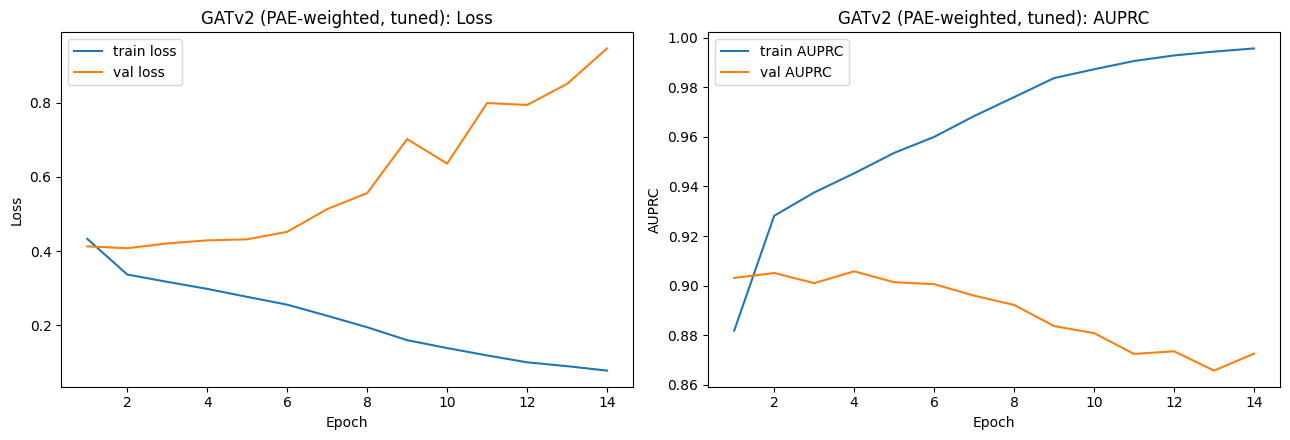

In [19]:
model_pae_final = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=True,
                                    hidden_dim=int(best_config["hidden_dim"]), dropout=best_config["dropout"])
model_pae_final, history_pae_final, _ = train_model(
    model_pae_final, "gatv2_pae_weighted_final", train_loader, val_loader, POS_WEIGHT,
    lr=best_config["lr"], weight_decay=best_config["weight_decay"])
plot_training_curves(history_pae_final, "GATv2 (PAE-weighted, tuned)")

[gatv2_unweighted_final] epoch  1: train_loss=0.4264 train_AUPRC=0.885 | val_loss=0.4055 val_AUPRC=0.907 val_AUROC=0.928
[gatv2_unweighted_final] epoch  2: train_loss=0.3334 train_AUPRC=0.929 | val_loss=0.4146 val_AUPRC=0.909 val_AUROC=0.930
[gatv2_unweighted_final] epoch  3: train_loss=0.3149 train_AUPRC=0.938 | val_loss=0.4299 val_AUPRC=0.908 val_AUROC=0.930
[gatv2_unweighted_final] epoch  4: train_loss=0.2911 train_AUPRC=0.948 | val_loss=0.4273 val_AUPRC=0.904 val_AUROC=0.927
[gatv2_unweighted_final] epoch  5: train_loss=0.2693 train_AUPRC=0.955 | val_loss=0.4454 val_AUPRC=0.900 val_AUROC=0.924
[gatv2_unweighted_final] epoch  6: train_loss=0.2430 train_AUPRC=0.962 | val_loss=0.4705 val_AUPRC=0.900 val_AUROC=0.924
[gatv2_unweighted_final] epoch  7: train_loss=0.2111 train_AUPRC=0.970 | val_loss=0.5652 val_AUPRC=0.896 val_AUROC=0.921
[gatv2_unweighted_final] epoch  8: train_loss=0.1820 train_AUPRC=0.977 | val_loss=0.5612 val_AUPRC=0.889 val_AUROC=0.914
[gatv2_unweighted_final] epoch  

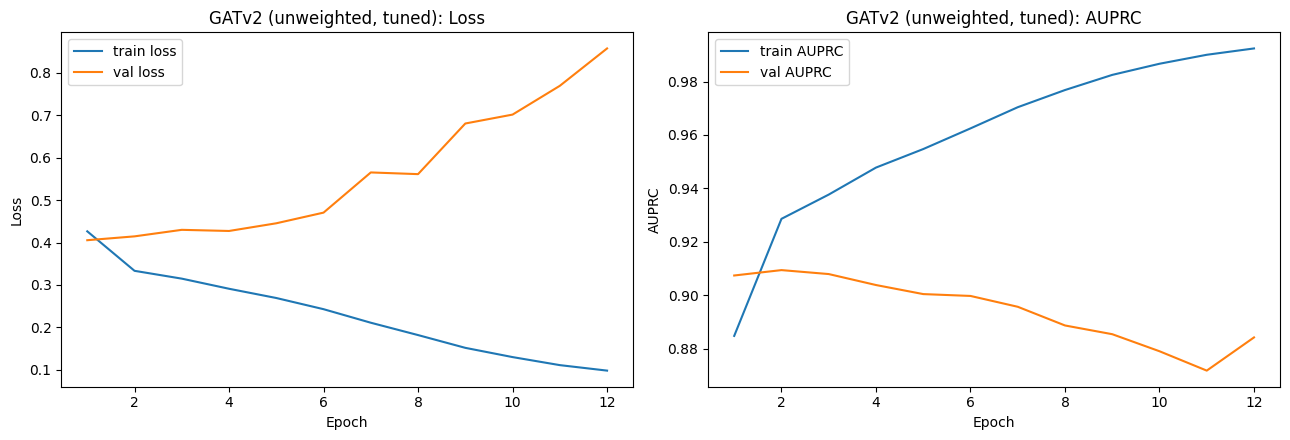

In [20]:
model_unw_final = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=False,
                                   hidden_dim=int(best_config["hidden_dim"]), dropout=best_config["dropout"])
model_unw_final, history_unw_final, _ = train_model(
    model_unw_final, "gatv2_unweighted_final", train_loader, val_loader, POS_WEIGHT,
    lr=best_config["lr"], weight_decay=best_config["weight_decay"])
plot_training_curves(history_unw_final, "GATv2 (unweighted, tuned)")

## 12. Final Comparison: All Models, Tuned Where Applicable

In [21]:
test_labels_pae_final, test_probs_pae_final = evaluate_gnn(model_pae_final, test_loader)
test_labels_unw_final, test_probs_unw_final = evaluate_gnn(model_unw_final, test_loader)
assert np.array_equal(test_labels_pae_final, test_labels_pae)

final_results = [r for r in initial_results if r["model"] in
                  ("GCN (baseline)", "GraphSAGE (baseline)", "XGBoost (structure-free baseline)")]
final_results.append({"model": "GATv2 (PAE-weighted, tuned)", **full_metrics(test_labels_pae, test_probs_pae_final)})
final_results.append({"model": "GATv2 (unweighted, tuned)", **full_metrics(test_labels_pae, test_probs_unw_final)})
final_results.append({"model": "GATv2 (PAE-weighted, original)", **full_metrics(test_labels_pae, test_probs_pae)})
final_results.append({"model": "GATv2 (unweighted, original)", **full_metrics(test_labels_pae, test_probs_unw)})

final_results_df = pd.DataFrame(final_results).sort_values("AUPRC", ascending=False)
final_results_df.to_csv("phase4_results_final.csv", index=False)
print(final_results_df.to_string(index=False))

                            model    AUPRC    AUROC  Precision   Recall       F1
             GraphSAGE (baseline) 0.914849 0.939311   0.799338 0.886197 0.840529
XGBoost (structure-free baseline) 0.912483 0.935387   0.826545 0.834435 0.830471
   GATv2 (PAE-weighted, original) 0.911198 0.937346   0.831836 0.849853 0.840748
     GATv2 (unweighted, original) 0.911158 0.935842   0.778497 0.882526 0.827254
        GATv2 (unweighted, tuned) 0.909695 0.935477   0.819048 0.852423 0.835402
      GATv2 (PAE-weighted, tuned) 0.906880 0.933899   0.819772 0.843245 0.831343
                   GCN (baseline) 0.893764 0.926464   0.808029 0.812775 0.810395


## 13. Statistical Significance Testing - Tuned Models
The same three paired tests as Section 9, now applied to the tuned models: does PAE-weighting still favour one side once both models get the same fair tuning treatment, how do the tuned models compare to the broader baseline set, and did tuning actually change anything relative to the original run?

In [22]:
significance_results_final = []
significance_results_final.append(run_all_significance_tests(
    "GATv2 (PAE-weighted, tuned)", test_probs_pae_final,
    "GATv2 (unweighted, tuned)", test_probs_unw_final, test_labels_pae))
significance_results_final.append(run_all_significance_tests(
    "GATv2 (PAE-weighted, tuned)", test_probs_pae_final,
    "GraphSAGE (baseline)", test_probs_sage, test_labels_pae))
significance_results_final.append(run_all_significance_tests(
    "GATv2 (PAE-weighted, tuned)", test_probs_pae_final,
    "XGBoost (structure-free baseline)", xgb_test_probs, test_labels_pae))
significance_results_final.append(run_all_significance_tests(
    "GATv2 (PAE-weighted, original)", test_probs_pae,
    "GATv2 (PAE-weighted, tuned)", test_probs_pae_final, test_labels_pae))

pd.DataFrame(significance_results_final).to_csv("phase4_significance_tests_final.csv", index=False)
print("\nSaved phase4_significance_tests_final.csv")


=== GATv2 (PAE-weighted, tuned)  vs.  GATv2 (unweighted, tuned) ===
McNemar's test           : statistic=0.880, p=0.3483
Paired bootstrap (AUPRC) : diff=-0.0028, 95% CI=[-0.0060, +0.0002], p=0.0730
DeLong's test (AUROC)    : z=-1.833, p=0.0668
-> NOT statistically significant difference between GATv2 (PAE-weighted, tuned) and GATv2 (unweighted, tuned) (alpha=0.05, using the more powerful rank-based tests)

=== GATv2 (PAE-weighted, tuned)  vs.  GraphSAGE (baseline) ===
McNemar's test           : statistic=0.511, p=0.4745
Paired bootstrap (AUPRC) : diff=-0.0079, 95% CI=[-0.0116, -0.0040], p=0.0000
DeLong's test (AUROC)    : z=-4.693, p=0.0000
-> STATISTICALLY SIGNIFICANT difference between GATv2 (PAE-weighted, tuned) and GraphSAGE (baseline) (alpha=0.05, using the more powerful rank-based tests)

=== GATv2 (PAE-weighted, tuned)  vs.  XGBoost (structure-free baseline) ===
McNemar's test           : statistic=0.015, p=0.9014
Paired bootstrap (AUPRC) : diff=-0.0055, 95% CI=[-0.0102, -0.000

## 14. 3-Fold Cross-Validation: How Much Does Performance Vary Across Splits?
Every result so far comes from **one** train/val/test split. A single test-set AUPRC cannot tell you how much that number would change if a different random set of proteins had been held out, which matters directly for how confidently the paper can state a single headline number.

### Why 3-fold here, not the more standard 5-fold or 10-fold
At ~31 minutes per epoch and ~10-15 epochs to convergence per run, each fold costs roughly the same as one full training run in Section 11 (a few hours). 5-fold would cost nearly double 3-fold for a diminishing-returns improvement in the precision of the variance estimate; 3-fold is the standard, accepted compromise when full k-fold is computationally constrained, and is enough to answer the actual question here: is the test AUPRC from Section 12 a stable estimate, or did this particular split happen to be unusually easy or hard?

### Why only the tuned PAE-weighted model, not every model
This is the model the paper's central claim rests on. Running every baseline through 3-fold CV as well would triple the cost of Sections 7-13 for a question (split-to-split variance) that matters most for the one model being put forward as the contribution.

### Implementation
Each fold uses a different random seed for `make_protein_split` (so a *different* set of proteins is held out each time, verified to produce genuinely different test sets, not the same split three times), retrains a fresh model from the winning Section 10 configuration to full convergence, and evaluates on that fold's own test set. We report the mean and standard deviation across folds, not just the three individual numbers.

In [18]:
CV_SEEDS = [42, 123, 7]  # seed 42 matches the main split already used above, for direct comparability
cv_results = []

for seed in CV_SEEDS:
    print(f"\n=== CV fold, seed={seed} ===")
    fold_train_df, fold_val_df, fold_test_df = make_protein_split(df, seed=seed)
    fold_train_loader, fold_val_loader, fold_test_loader = make_loaders(fold_train_df, fold_val_df, fold_test_df)
    fold_pos_weight = make_pos_weight(fold_train_df)

    fold_model = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=True,
                                  hidden_dim=int(best_config["hidden_dim"]), dropout=best_config["dropout"])
    fold_model, _, _ = train_model(
        fold_model, f"gatv2_pae_weighted_cv_seed{seed}", fold_train_loader, fold_val_loader, fold_pos_weight,
        lr=best_config["lr"], weight_decay=best_config["weight_decay"], verbose=False)

    fold_labels, fold_probs = evaluate_gnn(fold_model, fold_test_loader)
    fold_metrics = full_metrics(fold_labels, fold_probs)
    fold_metrics["seed"] = seed
    fold_metrics["n_test"] = len(fold_labels)
    cv_results.append(fold_metrics)
    print(f"  Fold result: {fold_metrics}")

cv_results_df = pd.DataFrame(cv_results)
summary_row = {
    "seed": "mean ± std", "n_test": "-",
    **{metric: f"{cv_results_df[metric].mean():.4f} ± {cv_results_df[metric].std():.4f}"
       for metric in ["AUPRC", "AUROC", "Precision", "Recall", "F1"]}
}
print("\n=== 3-Fold CV Summary (tuned PAE-weighted model) ===")
print(pd.concat([cv_results_df, pd.DataFrame([summary_row])], ignore_index=True).to_string(index=False))
cv_results_df.to_csv("phase4_cv_results.csv", index=False)
print("\nSaved phase4_cv_results.csv")


=== CV fold, seed=42 ===
  Fold result: {'AUPRC': 0.9076820051834206, 'AUROC': 0.9341547390844799, 'Precision': 0.8387096774193549, 'Recall': 0.8208516886930984, 'F1': 0.8296846011131725, 'seed': 42, 'n_test': 6771}

=== CV fold, seed=123 ===
  Fold result: {'AUPRC': 0.9101957021482586, 'AUROC': 0.9375172168073858, 'Precision': 0.8275664855590507, 'Recall': 0.8506760728982952, 'F1': 0.8389621684302073, 'seed': 123, 'n_test': 8159}

=== CV fold, seed=7 ===
  Fold result: {'AUPRC': 0.9054417604802802, 'AUROC': 0.9400004567094935, 'Precision': 0.8159073935772965, 'Recall': 0.8381281166091292, 'F1': 0.826868495742668, 'seed': 7, 'n_test': 6924}

=== 3-Fold CV Summary (tuned PAE-weighted model) ===
          AUPRC           AUROC       Precision          Recall              F1       seed n_test
       0.907682        0.934155         0.83871        0.820852        0.829685         42   6771
       0.910196        0.937517        0.827566        0.850676        0.838962        123   8159
  

## 15. Does the Model Understand *Why*? Error Analysis & Attention Inspection
A high AUPRC says the model ranks pathogenic variants above benign ones well, it does not by itself say *what* the model is using to make that judgement. This section looks under the hood of the tuned PAE-weighted model from Section 11 (the main-split version, not a CV fold, so it lines up with the error-analysis variant table used elsewhere in this notebook).

### 15a. Confusion matrix on the test set

In [23]:
best_pae_probs = test_probs_pae_final
best_pae_model = model_pae_final

preds = (best_pae_probs >= 0.5).astype(int)
cm = confusion_matrix(test_labels_pae, preds)
print("Confusion matrix (rows=actual, cols=predicted), [[TN, FP], [FN, TP]]:")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\nPrecision={precision_score(test_labels_pae, preds):.3f}, "
      f"Recall={recall_score(test_labels_pae, preds):.3f}, F1={f1_score(test_labels_pae, preds):.3f}")

Confusion matrix (rows=actual, cols=predicted), [[TN, FP], [FN, TP]]:
[[3542  505]
 [ 427 2297]]

Precision=0.820, Recall=0.843, F1=0.831


### 15b. The model's most confident mistakes

In [24]:
all_uniprot, all_varid = [], []
for batch in test_loader:
    all_uniprot.extend(batch.uniprot_id)
    all_varid.extend(batch.variation_id)

error_df = pd.DataFrame({
    "VariationID": all_varid, "UniProt_ID": all_uniprot,
    "true_label": test_labels_pae, "predicted_prob": best_pae_probs,
})
error_df["abs_error"] = (error_df["true_label"] - error_df["predicted_prob"]).abs()

print("Top 10 most confident mistakes (model very sure, but wrong):")
print(error_df.sort_values("abs_error", ascending=False).head(10).to_string(index=False))

print("\nTest-set error by protein (proteins with >= 5 test variants, worst-performing first):")
per_protein = error_df.groupby("UniProt_ID").apply(
    lambda g: pd.Series({"n": len(g), "mean_abs_error": g["abs_error"].mean()}), include_groups=False
)
print(per_protein[per_protein["n"] >= 5].sort_values("mean_abs_error", ascending=False).head(10))

Top 10 most confident mistakes (model very sure, but wrong):
 VariationID UniProt_ID  true_label  predicted_prob  abs_error
      258400     Q14055         0.0        0.998828   0.998828
      340312     P12109         0.0        0.997978   0.997978
        9269     P37088         0.0        0.997318   0.997318
     1541471     P00558         0.0        0.996837   0.996837
      876392     Q14055         0.0        0.996772   0.996772
      789279     Q15848         0.0        0.996263   0.996263
       35665     O43918         1.0        0.004041   0.995959
      225031     Q9ULD0         0.0        0.995790   0.995790
     2170194     P35227         0.0        0.995115   0.995115
      220955     Q9UI46         0.0        0.995027   0.995027

Test-set error by protein (proteins with >= 5 test variants, worst-performing first):
               n  mean_abs_error
UniProt_ID                      
Q6P2Q9      13.0        0.755561
Q16586      35.0        0.631458
O75569       7.0        0.6

### 15c. What is the attention mechanism actually focusing on?
For one real test-set variant, we extract GATv2's learned attention weights on the mutated residue's incoming edges and rank its structural neighbors by how much attention the model paid them.

In [25]:
example_row = test_df.iloc[0]
example_ds = MissenseVariantGraphDataset(test_df.iloc[[0]], GRAPH_DIR)
example_data = example_ds[0].to(DEVICE)
example_batch = Batch.from_data_list([example_data])

best_pae_model.eval()
with torch.no_grad():
    logit, (edge_index_1, alpha_1, edge_index_2, alpha_2) = best_pae_model(example_batch, return_attention=True)

variant_node = example_data.variant_node_idx.item()
incoming_mask = edge_index_1[1] == variant_node
neighbor_nodes = edge_index_1[0][incoming_mask].cpu().numpy()
neighbor_attention = alpha_1[incoming_mask].mean(dim=1).cpu().numpy()

attn_df = pd.DataFrame({"neighbor_residue": neighbor_nodes + 1, "attention_weight": neighbor_attention})
attn_df = attn_df.sort_values("attention_weight", ascending=False)

print(f"Variant: {example_row['UniProt_ID']} {example_row['Ref_AA']}{example_row['Pos']}{example_row['Alt_AA']} "
      f"(true label: {'Pathogenic' if example_row['Target']==1 else 'Benign'}, "
      f"predicted probability: {torch.sigmoid(logit).item():.3f})")
print(f"\nLayer-1 attention from the mutated residue's {len(attn_df)} structural neighbors:")
print(attn_df.to_string(index=False))

Variant: P06132 Gly281Val (true label: Pathogenic, predicted probability: 0.975)

Layer-1 attention from the mutated residue's 14 structural neighbors:
 neighbor_residue  attention_weight
              302          0.402637
              281          0.133322
              279          0.131484
              301          0.104020
              259          0.047739
              304          0.046265
              260          0.042336
              303          0.029190
              261          0.022483
              262          0.010566
              282          0.010530
              283          0.007981
              280          0.007157
              338          0.004290


## 16. Not Yet Included in this notebook: Flagged as Future Work, implemented in Phase 5
A direct comparison against AlphaMissense's published scores on the same test variants is **not** part of this notebook. That requires sourcing AlphaMissense's precomputed score table and joining it to `test_df` by variant, a clean, separate task (Phase 5) once this model's own results are finalized.

Also out of scope given the project timeline, and explicitly noted as such rather than silently skipped: an exhaustive hyperparameter grid search (Section 10 used a constrained 6-configuration search instead), 5-fold or 10-fold cross-validation (Section 14 used 3-fold), and cross-validating every baseline architecture rather than only the proposed model.

## 17. Methods Summary (Copy-Paste for the Paper)
> Proteins were split into training, validation, and test sets (70/15/15) at the protein level (by UniProt accession) to prevent data leakage between variants sharing the same structural graph; disjointness was verified programmatically. Batches were constructed using a node-budget sampler bounding total residue count per batch rather than a fixed number of graphs, keeping peak GPU memory bounded given the wide range of protein sizes (up to 2,699 residues). The proposed model was a two-layer GATv2 (Brody et al., 2022) in which edge attention was conditioned on AlphaFold's Cα distance and Predicted Aligned Error (PAE) between residue pairs; the mutated residue's post-message-passing embedding was extracted and passed to an MLP classifier rather than pooling over the full graph. Class imbalance was addressed via a positive-class weight in the loss. Four baselines isolated each architectural choice: an identical GATv2 with edge features withheld (testing PAE-weighting specifically), a GCN and a GraphSAGE model (Hamilton et al., 2017) testing the contribution of attention against two architecturally distinct non-attention alternatives, and an XGBoost classifier on the variant residue's ESM-2 embedding and amino-acid identity alone with no structural graph (testing structure itself). An initial training pass showed all models within ~0.01-0.02 AUPRC of one another, with the GNNs overfitting within 1-3 epochs. This was addressed with a constrained hyperparameter search (6 configurations spanning learning rate, dropout, hidden dimensionality, and weight decay, each evaluated over a short 5-epoch budget given the observed early overfitting) for the PAE-weighted model, with the winning configuration then applied identically to its unweighted ablation and both retrained to full convergence with early stopping. Pairwise model comparisons were evaluated for statistical significance using three paired tests on the held-out test set: McNemar's test (McNemar, 1947), a paired bootstrap test on the AUPRC difference (2,000 resamples), and DeLong's test (DeLong et al., 1988) for correlated AUROC curves. Finally, the tuned PAE-weighted model's robustness to the choice of train/test split was assessed via 3-fold cross-validation (three independent protein-level splits, each with the model retrained to convergence), reporting mean ± standard deviation across folds rather than a single split's point estimate.